## 1. Instalacja bibliotek


In [7]:
! pip install requests beautifulsoup4 pandas matplotlib seaborn numpy


[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


## 2. Import bibliotek

In [20]:
import requests
from bs4 import BeautifulSoup
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import time
import os
import pprint

## 3. Konfiguracja

In [9]:
MAX_STRON = 15          
PAUZA_SEKUND = 3     # zeby nie blokowalo requestow
FOLDER_DANYCH = "dane_otodom"

HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/120.0.0.0 Safari/537.36"
    ),
    "Accept-Language": "pl-PL,pl;q=0.9",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8",
}

URL_BAZA = (
    "https://www.otodom.pl/pl/wyniki/sprzedaz/mieszkanie/"
    "malopolskie/krakow/krakow/krakow"
)


## 4. Funkcja pobierająca ogłoszenia z jednej strony

In [10]:
def pobierz_ogloszenia_ze_strony(numer_strony):

    url = f"{URL_BAZA}?limit=36&page={numer_strony}"

    try:
        response = requests.get(url, headers=HEADERS, timeout=15)
    except requests.RequestException as e:
        print(f"  BŁĄD połączenia: {e}")
        return []

    print(f"  Status HTTP: {response.status_code}")
    
    soup = BeautifulSoup(response.text, "html.parser")
    tag = soup.find("script", {"id": "__NEXT_DATA__"})

    dane_json = json.loads(tag.string)

    items = dane_json["props"]["pageProps"]["data"]["searchAds"]["items"]

    print(f"  liczba ogloszen: {len(items)} ")
    return items

## 5. Funkcja wyciągająca dane z jednego ogłoszenie

In [11]:
# Mapowanie angielskich nazw pięter na liczby
PIETRO_MAP = {
    "GROUND": 0,
    "FIRST": 1,
    "SECOND": 2,
    "THIRD": 3,
    "FOURTH": 4,
    "FIFTH": 5,
    "SIXTH": 6,
    "SEVENTH": 7,
    "EIGHTH": 8,
    "NINTH": 9,
    "TENTH": 10,
    "ABOVE_TENTH": 11,
}

def wyciagnij_dane_ogloszenia(item):
    
    # Cena
    cena_raw = item.get("totalPrice") or {}
    cena = cena_raw.get("value")

    # Powierzchnia
    powierzchnia = item.get("areaInSquareMeters")

    # Cena za m²
    if cena and powierzchnia and powierzchnia > 0:
        cena_za_m2 = round(cena / powierzchnia, 0)
    else:
        cena_za_m2 = None

    # Piętro 
    pietro_tekst = item.get("floorNumber")
    pietro = PIETRO_MAP.get(pietro_tekst) if pietro_tekst else None

    # Data dodania 
    data_raw = item.get("dateCreated", "")
    data = data_raw[:10] if data_raw else None  # tu zmieniamy format 

    # Link
    slug = item.get("slug", "")
    link = f"https://www.otodom.pl/pl/oferta/{slug}" if slug else None

    return {
        "id": item.get("id"),
        "tytul": item.get("title"),
        "cena_pln": cena,
        "powierzchnia_m2": powierzchnia,
        "cena_za_m2": cena_za_m2,
        "liczba_pokoi": item.get("roomsNumber"),
        "pietro": pietro,
        "data_dodania": data,
        "link": link,
    }

## 6. Główna pętla scrapowania

In [ ]:
wszystkie_ogloszenia = []
surowe_wszystkie = []  # zachowujemy też surowe dane na wypadek gdybyśmy chcieli coś sprawdzić

for numer_strony in range(1, MAX_STRON + 1):
    print(f"\n[Strona {numer_strony}/{MAX_STRON}]")

    surowe = pobierz_ogloszenia_ze_strony(numer_strony)

    if not surowe:
        print(" Brak ogłoszeń ")
        break

    surowe_wszystkie.extend(surowe)

    for item in surowe:
        wszystkie_ogloszenia.append(wyciagnij_dane_ogloszenia(item))

    if numer_strony < MAX_STRON:
        time.sleep(PAUZA_SEKUND)

print(f"Znaleziono łącznie: {len(wszystkie_ogloszenia)} ogłoszeń")


[Strona 1/15]
  Status HTTP: 200
  liczba ogloszen: 32 

[Strona 2/15]
  Status HTTP: 200
  liczba ogloszen: 36 

[Strona 3/15]
  Status HTTP: 200
  liczba ogloszen: 34 

[Strona 4/15]
  Status HTTP: 200
  liczba ogloszen: 33 

[Strona 5/15]
  Status HTTP: 200
  liczba ogloszen: 36 

[Strona 6/15]
  Status HTTP: 200
  liczba ogloszen: 35 

[Strona 7/15]
  Status HTTP: 200
  liczba ogloszen: 32 

[Strona 8/15]
  Status HTTP: 200
  liczba ogloszen: 34 

[Strona 9/15]
  Status HTTP: 200
  liczba ogloszen: 29 

[Strona 10/15]
  Status HTTP: 200
  liczba ogloszen: 30 

[Strona 11/15]
  Status HTTP: 200
  liczba ogloszen: 30 

[Strona 12/15]
  Status HTTP: 200
  liczba ogloszen: 27 

[Strona 13/15]
  Status HTTP: 200
  liczba ogloszen: 37 

[Strona 14/15]
  Status HTTP: 200
  liczba ogloszen: 34 
Znaleziono łącznie: 459 ogłoszeń


In [21]:
pprint.pprint(surowe_wszystkie[0])

{'__typename': 'AdvertListItem',
 'advertOwner': {'__typename': 'LegacyAdvertOwner',
                 'contacts': [],
                 'imageUrl': 'https://ireland.apollo.olxcdn.com/v1/files/eyJmbiI6Imk3bW1jNm9wZDI2MzEtQVBMIn0.PtmiRsE_k91ose890zmw9Ld_GdPGBZWFOT-IMIF2RxM/image;s=97x97;q=100',
                 'name': 'Damian Siwiec'},
 'agency': {'__typename': 'AgencyListingDetails',
            'brandingVisible': True,
            'enhancedBrandingFeatures': ['ENHANCED_BRANDING_SELLER_TYPE',
                                         'ENHANCED_BRANDING_LOGO_DISPLAY',
                                         'ENHANCED_BRANDING_COMPANY_NAME'],
            'highlightedAds': False,
            'id': 11366223,
            'imageUrl': None,
            'name': 'CBG sp. z o.o.',
            'slug': 'cbg-sp-z-o-o-ID11366223',
            'type': 'AGENCY'},
 'areaInSquareMeters': 54.62,
 'createdAtFirst': '2026-06-03T16:58:26Z',
 'dateCreated': '2026-06-03 16:58:36',
 'development': None,
 'devel

## 7. Zapis danych

In [13]:
if not os.path.exists(FOLDER_DANYCH):
    os.mkdir(FOLDER_DANYCH)

# CSV
df = pd.DataFrame(wszystkie_ogloszenia)
sciezka_csv = os.path.join(FOLDER_DANYCH, "mieszkania_krakow.csv")
df.to_csv(sciezka_csv, index=False, encoding="utf-8-sig") # zeby byly poslkie znaki
print(f"Ścieka CSV:  {sciezka_csv}")

Ścieka CSV:  dane_otodom/mieszkania_krakow.csv


## 8. Podgląd i kontrola jakości danych

In [14]:
df.head()


,id,tytul,cena_pln,powierzchnia_m2,cena_za_m2,liczba_pokoi,pietro,data_dodania,link
0,68075205,Nowe/ Dolina Prądnika,766250.0,54.62,14029.0,THREE,3.0,2026-06-03,https://www.otodom.pl/pl/oferta/nowe-dolina-pr...
1,66193139,ul. Powstańców / os. Piastów,NaN,NaN,NaN,None,NaN,2024-12-03,https://www.otodom.pl/pl/oferta/ul-powstancow-...
2,66295333,Białoprądnicka Park,NaN,NaN,NaN,None,NaN,2025-01-08,https://www.otodom.pl/pl/oferta/bialopradnicka...
3,67933585,"3 pokoje, dużo zieleni",599900.0,46.60,12873.0,THREE,6.0,2026-06-03,https://www.otodom.pl/pl/oferta/3-pokoje-duzo-...
4,68023232,3 pokoje | 6 piętro | narożne | widok i światł...,929000.0,56.59,16416.0,THREE,6.0,2026-06-03,https://www.otodom.pl/pl/oferta/3-pokoje-6-pie...


In [15]:
print("Brakujące wartości:")
print(df.isnull().sum())
print()
print("Podstawowe statystyki:")
df[["cena_pln", "powierzchnia_m2", "cena_za_m2", "liczba_pokoi", "pietro"]].describe().round(0)

Brakujące wartości:
id                  0
tytul               0
cena_pln           52
powierzchnia_m2    41
cena_za_m2         52
liczba_pokoi       41
pietro             43
data_dodania        0
link                0
dtype: int64

Podstawowe statystyki:


,cena_pln,powierzchnia_m2,cena_za_m2,pietro
count,426.0,437.0,426.0,435.0
mean,990043.0,61.0,16634.0,2.0
std,616367.0,55.0,4231.0,2.0
min,260000.0,14.0,1530.0,0.0
25%,659250.0,40.0,14000.0,1.0
50%,820905.0,54.0,15856.0,2.0
75%,1093476.0,67.0,18191.0,3.0
max,6500000.0,1072.0,33950.0,11.0


## 9. Analiza i wykresy

### 9.1 — Rozkład cen za m²

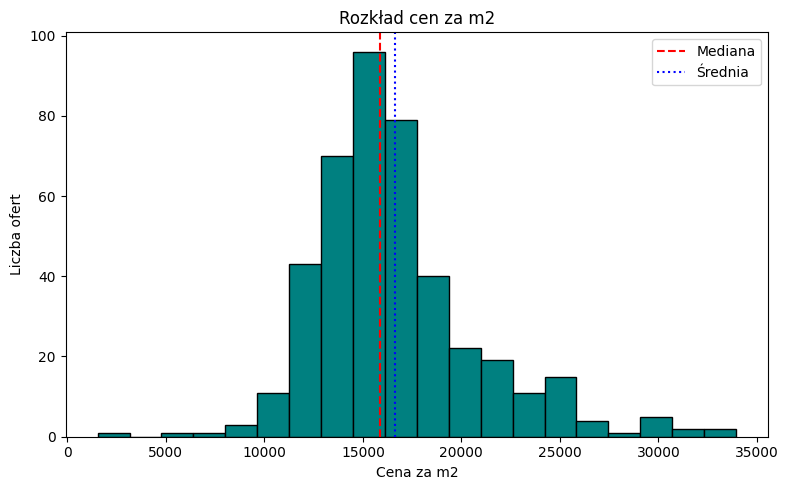

In [16]:
import matplotlib.pyplot as plt

df_cena = df["cena_za_m2"].dropna()

if df_cena.empty:
    print("Brak danych.")
else:
    mediana = df_cena.median()
    srednia = df_cena.mean()

    plt.figure(figsize=(8, 5))
    
    plt.hist(df_cena, bins=20, color='teal', edgecolor='black')
    
    plt.axvline(mediana, color='red', linestyle='dashed', label='Mediana')
    plt.axvline(srednia, color='blue', linestyle='dotted', label='Średnia')
    
    plt.title("Rozkład cen za m2")
    plt.xlabel("Cena za m2")
    plt.ylabel("Liczba ofert")
    plt.legend()
    
    plt.tight_layout()
    plt.savefig("wykres_cen.png")
    plt.show()

### 9.2 — Cena za m² wg piętra

In [25]:
liczba_mieszkan_na_pietro = df.dropna(subset=["pietro"])["pietro"].value_counts().sort_index()
print(liczba_mieszkan_na_pietro)

pietro
0.0      88
1.0     123
2.0      59
3.0      59
4.0      48
5.0      16
6.0      16
7.0       7
8.0       5
9.0       5
10.0      3
11.0      6
Name: count, dtype: int64


Statystyki cen wg pięter:
        srednia    n
pietro              
0.0     16320.0   87
1.0     16683.0  122
2.0     16749.0   59
3.0     16022.0   57
4.0     16728.0   43
5.0     18720.0   15
6.0     17864.0   15
7.0     16522.0    7
8.0     15532.0    5
9.0     16906.0    5
10.0    20557.0    3
11.0    13719.0    6


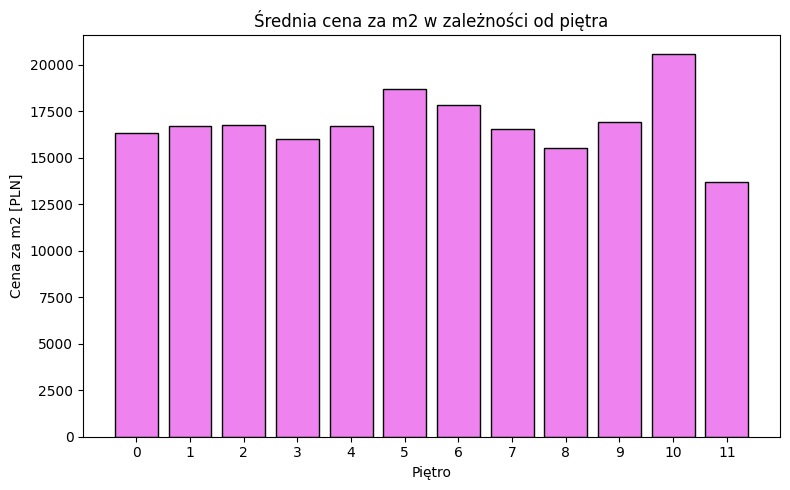

In [18]:
df_pietro = df.dropna(subset=["pietro", "cena_za_m2"])
df_pietro = df_pietro[df_pietro["pietro"] <= 11]

if df_pietro.empty:
    print("Brak danych do wykresu piętra.")
else:
    pietro_srednia = (
        df_pietro
        .groupby("pietro")["cena_za_m2"]
        .agg(["mean", "count"])
        .rename(columns={"mean": "srednia", "count": "n"})
        .query("n >= 2")
        .round(0)
    )
    
    print("Statystyki cen wg pięter:")
    print(pietro_srednia)

    if pietro_srednia.empty:
        print("Za mało danych na poszczególnych piętrach.")
    else:
        plt.figure(figsize=(8, 5))
        
        # Wykres słupkowy (tamten poprzedni wskazywal jakby kazde pietro bylo ze soba bezposrednio polaczone)
        plt.bar(pietro_srednia.index, pietro_srednia["srednia"], color='violet', edgecolor='black')
        
        plt.title("Średnia cena za m2 w zależności od piętra")
        plt.xlabel("Piętro")
        plt.ylabel("Cena za m2 [PLN]")
        plt.xticks(pietro_srednia.index)
        
        plt.tight_layout()
        plt.savefig("cena_wg_pietra.png")
        plt.show()

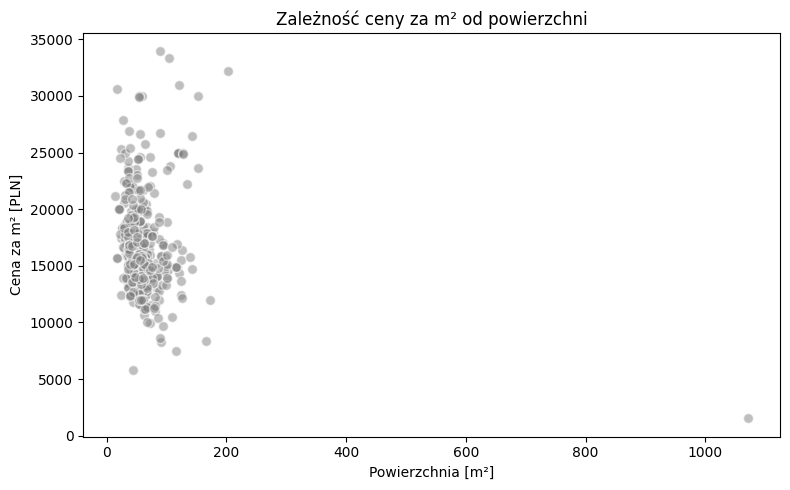

In [22]:
df_wykres1 = df.dropna(subset=["powierzchnia_m2", "cena_za_m2"])

plt.figure(figsize=(8, 5))

plt.scatter(df_wykres1["powierzchnia_m2"], df_wykres1["cena_za_m2"], 
            alpha=0.5, color="gray", edgecolors="white", s=50)
# zrezygnowalismy z lini trendu regploy - bo w naszym przypadku cena mieszkan nie jest liniowa
plt.title("Zależność ceny za m² od powierzchni")
plt.xlabel("Powierzchnia [m²]")
plt.ylabel("Cena za m² [PLN]")


plt.tight_layout()
plt.savefig("zaleznosc_ceny_powierzchni.png")
plt.show()


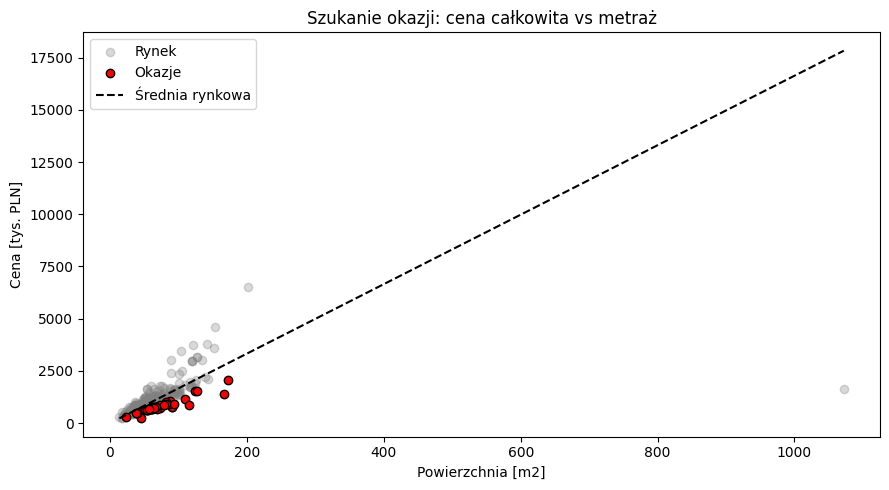

Znaleziono 47 okazji:


,tytul,powierzchnia_m2,cena_pln,odchylenie_procentowe,link
150,"TBS Bujaka 6A/24 – 44,7 m², 2 pokoje z balkone...",44.70,260000.0,-65.0%,https://www.otodom.pl/pl/oferta/tbs-bujaka-6a-...
215,Odbierz klucze już w I kwartale 2027 roku! Dom...,115.34,861169.0,-55.1%,https://www.otodom.pl/pl/oferta/odbierz-klucze...
41,"Ciche, bezczynszowe 90m2 w domu, do remontu, 2...",90.50,750000.0,-50.2%,https://www.otodom.pl/pl/oferta/ciche-bezczyns...
108,Dwupoziomowe mieszkanie | 166 m² | Nowa Huta,166.00,1390000.0,-49.7%,https://www.otodom.pl/pl/oferta/dwupoziomowe-m...
129,Przestronne mieszkanie z ogrodem i garażem w K...,89.88,775000.0,-48.2%,https://www.otodom.pl/pl/oferta/przestronne-mi...
441,Glogera • 2 poziomy • 3 pokoje • 2 łazienki • ...,94.18,909700.0,-41.9%,https://www.otodom.pl/pl/oferta/glogera-2-pozi...
133,✔ 3M | 9 986 zł za m2! | Zakopiańska!,73.00,729000.0,-40.0%,https://www.otodom.pl/pl/oferta/3m-9-986-zl-za...
260,3 pokojowe mieszkanie z osobną kuchnią oraz pi...,68.00,680000.0,-39.9%,https://www.otodom.pl/pl/oferta/3-pokojowe-mie...
244,Mieszkanie 3-pokojowe z balkonem w Nowej Hucie,86.36,899000.0,-37.4%,https://www.otodom.pl/pl/oferta/mieszkanie-3-p...
95,6-Pokojowe W Dobrej Lokalizacji I Cenie,110.00,1150000.0,-37.1%,https://www.otodom.pl/pl/oferta/6-pokojowe-w-d...


In [23]:
df_okazje = df.dropna(subset=["powierzchnia_m2", "cena_pln", "link"]).copy()
srednia_cena_metra = df_okazje["cena_za_m2"].mean()
df_okazje["cena_teoretyczna"] = df_okazje["powierzchnia_m2"] * srednia_cena_metra
df_okazje["odchylenie_procentowe"] = ((df_okazje["cena_pln"] - df_okazje["cena_teoretyczna"]) / df_okazje["cena_teoretyczna"]) * 100

PROG_OKAZJI = -25
okazje_df = df_okazje[(df_okazje["odchylenie_procentowe"] <= PROG_OKAZJI) & (df_okazje["odchylenie_procentowe"] > -80)]

plt.figure(figsize=(9, 5))

# Wszystkie mieszkania 
plt.scatter(df_okazje["powierzchnia_m2"], df_okazje["cena_pln"] / 1000, 
            alpha=0.3, color="gray", label="Rynek")

# Ceny okazyjne
plt.scatter(okazje_df["powierzchnia_m2"], okazje_df["cena_pln"] / 1000, 
            color="red", edgecolor="black", label="Okazje")


X_wzorzec = np.linspace(df_okazje["powierzchnia_m2"].min(), df_okazje["powierzchnia_m2"].max(), 100)
Y_wzorzec = (X_wzorzec * srednia_cena_metra) / 1000
plt.plot(X_wzorzec, Y_wzorzec, color="black", linestyle="--", label="Średnia rynkowa")

plt.title("Szukanie okazji: cena całkowita vs metraż")
plt.xlabel("Powierzchnia [m2]")
plt.ylabel("Cena [tys. PLN]")
plt.legend()

plt.tight_layout()
plt.savefig("okazje_cenowe.png")
plt.show()


print(f"Znaleziono {len(okazje_df)} okazji:")
kolumny = ["tytul", "powierzchnia_m2", "cena_pln", "odchylenie_procentowe", "link"]
wynikowe_okazje = okazje_df[kolumny].sort_values(by="odchylenie_procentowe")
wynikowe_okazje["odchylenie_procentowe"] = wynikowe_okazje["odchylenie_procentowe"].round(1).astype(str) + "%"


display(wynikowe_okazje)